In [1]:
# Student Name: Mohammad Abdalrouf Alnaghmoush
# Student ID: 2230004028


# Lab 11: Attention


**Dataset:** This notebook uses the original [Lab 11 Q&A dataset](https://github.com/MohammedMosuily/NLP_lab11/blob/main/dataset/Lab_11_QnA_Dataset.csv) (168 questions, 12 answer groups). The CSV is included alongside this notebook under `dataset/`. All displayed attention charts and statistics are calculated by running the RNN on these examples. The displayed classification accuracy is on the training data only; it is not a generalization estimate.


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [2]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn

torch.manual_seed(42)
np.random.seed(42)
torch.set_num_threads(2)
print("PyTorch version:", torch.__version__)


PyTorch version: 2.15.0+cpu


## Step 2 — Upload the dataset

In [3]:
# Use the original CSV from the provided Lab 11 repository.
dataset_path = Path("dataset/Lab_11_QnA_Dataset.csv")
assert dataset_path.is_file(), f"Required dataset is missing: {dataset_path}"

df = pd.read_csv(dataset_path)
assert set(["question", "answer_id", "answer"]).issubset(df.columns)
assert df[["question", "answer_id", "answer"]].notna().all().all()
df["answer_id"] = df["answer_id"].astype(int)
df["question"] = df["question"].astype(str)

print("Dataset:", dataset_path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
print("Questions per group:")
print(df.groupby("answer_id").size().to_string())
display(df.head())


Dataset: dataset/Lab_11_QnA_Dataset.csv
Number of questions: 168
Number of answer groups: 12
Questions per group:
answer_id
0     14
1     14
2     14
3     14
4     14
5     14
6     14
7     14
8     14
9     14
10    14
11    14


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [4]:
# 1. Lowercase every question and remove punctuation.
def tokenize(text):
    return re.findall(r"[a-z0-9]+", str(text).lower())

df["tokens"] = df["question"].map(tokenize)
assert df["tokens"].map(len).min() > 0, "Unexpected empty question"

# 2. Give each word its own integer ID; 0 is reserved for padding.
vocabulary = sorted({token for question in df["tokens"] for token in question})
word_to_id = {token: i + 1 for i, token in enumerate(vocabulary)}

# 3. Pad every question to the length of the longest question.
max_length = int(df["tokens"].map(len).max())
sequences = [[word_to_id[token] for token in tokens] for tokens in df["tokens"]]
padded = [seq + [0] * (max_length - len(seq)) for seq in sequences]

label_values = sorted(df["answer_id"].unique())
label_to_index = {value: i for i, value in enumerate(label_values)}
index_to_label = {i: value for value, i in label_to_index.items()}

X = torch.tensor(padded, dtype=torch.long)
y = torch.tensor([label_to_index[v] for v in df["answer_id"]], dtype=torch.long)
label_to_answer = df.drop_duplicates("answer_id").set_index("answer_id")["answer"].to_dict()

print("Unique words:", len(vocabulary))
print("Longest question:", max_length, "tokens")
print("Input shape:", tuple(X.shape))
print("Label shape:", tuple(y.shape))
print("Padding ID: 0; tokens from the CSV are used without adding synthetic questions.")


Unique words: 225
Longest question: 11 tokens
Input shape: (168, 11)
Label shape: (168,)
Padding ID: 0; tokens from the CSV are used without adding synthetic questions.


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
class AttentionRNN(nn.Module):
    def __init__(self, vocab_size, n_classes, embedding_dim=32, hidden_dim=64):
        super().__init__()
        self.emb = nn.Embedding(vocab_size + 1, embedding_dim, padding_idx=0)
        # batch_first=True means (batch, sequence_length, features).
        self.rnn = nn.RNN(embedding_dim, hidden_dim, batch_first=True)
        self.att = nn.Linear(hidden_dim, 1)
        self.fc = nn.Linear(hidden_dim, n_classes)

    def forward(self, x):
        embedded = self.emb(x)
        hidden_states, _ = self.rnn(embedded)

        # Padding tokens must NOT receive attention.
        scores = self.att(hidden_states).squeeze(-1)
        scores = scores.masked_fill(x.eq(0), torch.finfo(scores.dtype).min)
        weights = torch.softmax(scores, dim=1)

        context = torch.bmm(weights.unsqueeze(1), hidden_states).squeeze(1)
        logits = self.fc(context)
        return logits, weights

model = AttentionRNN(len(vocabulary), len(label_values))
print(model)


AttentionRNN(
  (emb): Embedding(226, 32, padding_idx=0)
  (rnn): RNN(32, 64, batch_first=True)
  (att): Linear(in_features=64, out_features=1, bias=True)
  (fc): Linear(in_features=64, out_features=12, bias=True)
)


## Step 5 — Train the model
The model learns which answer belongs to each question.

Epoch   1/200 | loss=2.4949 | training accuracy=7.14%
Epoch  40/200 | loss=0.0117 | training accuracy=99.40%
Epoch  80/200 | loss=0.0085 | training accuracy=100.00%


Epoch 120/200 | loss=0.0005 | training accuracy=100.00%
Epoch 160/200 | loss=0.0003 | training accuracy=100.00%
Epoch 200/200 | loss=0.0002 | training accuracy=100.00%
Finished training on 168 real questions.
Final training accuracy: 100.00% (not test accuracy)
Attention weights sum to one: True
Max attention on padding: 0.0


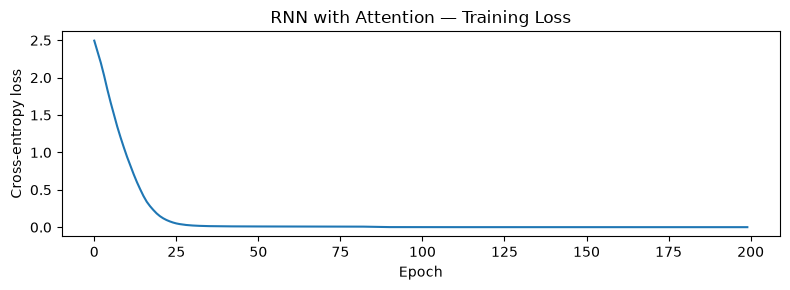

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()
loss_history = []

model.train()
for epoch in range(1, 201):
    # Reset accumulated gradients on EVERY optimization step.
    optimizer.zero_grad()
    logits, attention = model(X)
    loss = criterion(logits, y)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()
    loss_history.append(loss.item())

    if epoch == 1 or epoch % 40 == 0:
        accuracy = (logits.argmax(dim=1) == y).float().mean().item()
        print(f"Epoch {epoch:3d}/200 | loss={loss.item():.4f} | training accuracy={accuracy:.2%}")

model.eval()
with torch.no_grad():
    logits, attention = model(X)
    training_accuracy = (logits.argmax(dim=1) == y).float().mean().item()
    attention_sum = attention.sum(dim=1)
    pad_attention = attention.masked_select(X.eq(0))

print(f"Finished training on {len(df)} real questions.")
print(f"Final training accuracy: {training_accuracy:.2%} (not test accuracy)")
print("Attention weights sum to one:", torch.allclose(attention_sum, torch.ones_like(attention_sum), atol=1e-5))
print("Max attention on padding:", float(pad_attention.max()) if pad_attention.numel() else 0.0)

plt.figure(figsize=(8, 3))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("RNN with Attention — Training Loss")
plt.tight_layout()
plt.show()


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

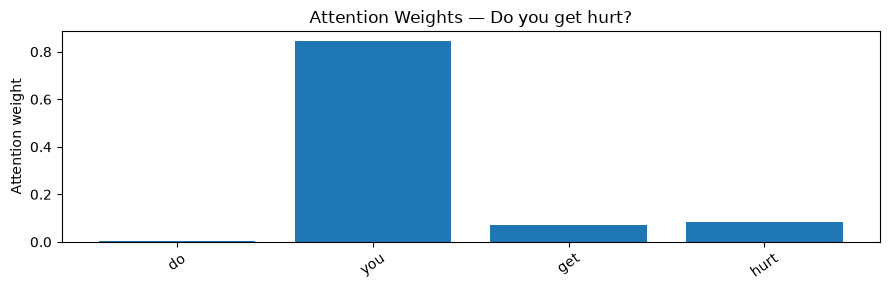

Original question: Do you get hurt?
Highest-attention word: you
Highest weight: 0.8437
Predicted answer group: 0
Predicted answer: I don't have a body.


In [7]:
# Visualize the weights of the first ORIGINAL question.
row_index = 0
question = df.loc[row_index, "question"]
words = df.loc[row_index, "tokens"]

with torch.no_grad():
    prediction, weights = model(X[row_index:row_index + 1])

weights_for_words = weights[0, :len(words)].cpu().numpy()
best_position = int(np.argmax(weights_for_words))
predicted_label = index_to_label[int(prediction.argmax(dim=1).item())]

plt.figure(figsize=(9, 3))
plt.bar(range(len(words)), weights_for_words)
plt.xticks(range(len(words)), words, rotation=35)
plt.title("Attention Weights — " + question)
plt.ylabel("Attention weight")
plt.tight_layout()
plt.show()

print("Original question:", question)
print("Highest-attention word:", words[best_position])
print("Highest weight:", round(float(weights_for_words[best_position]), 4))
print("Predicted answer group:", predicted_label)
print("Predicted answer:", label_to_answer[predicted_label])


## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

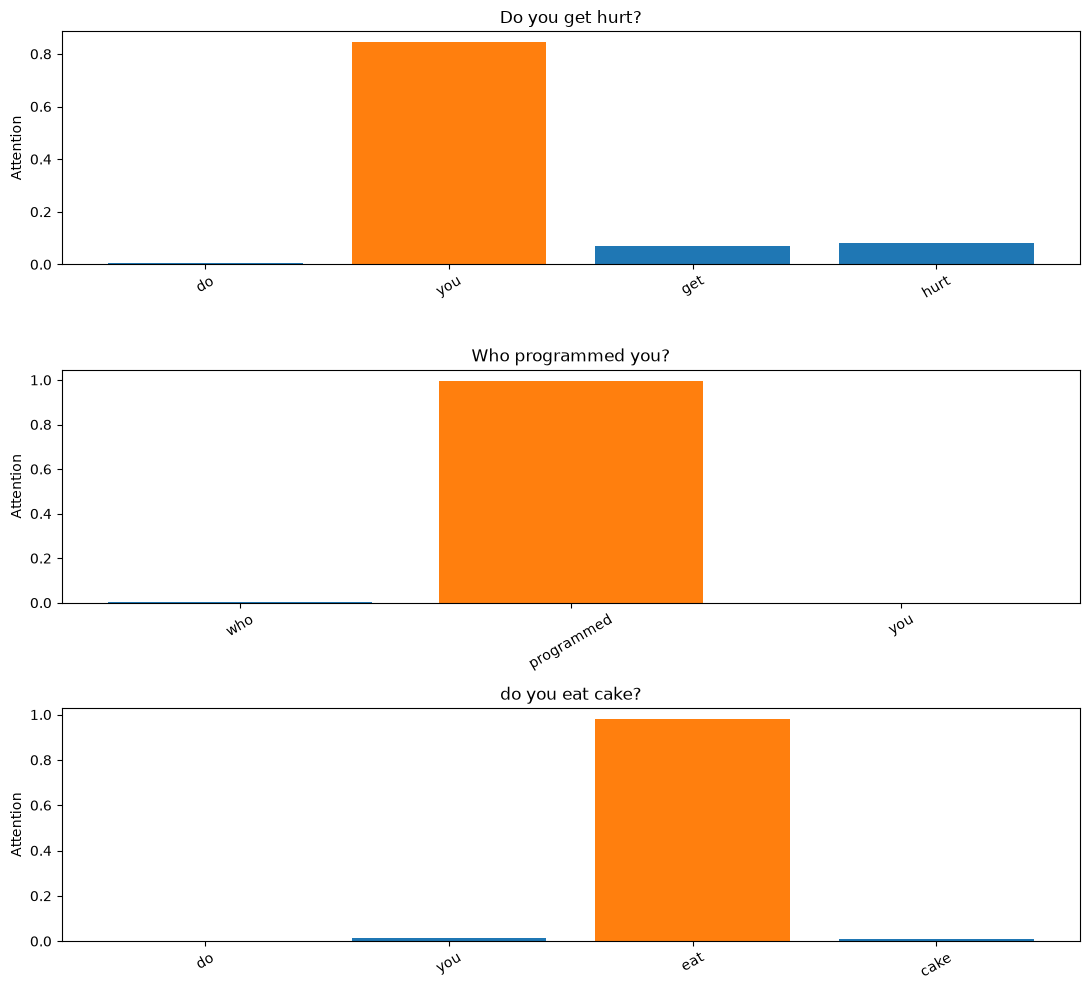

Question: Do you get hurt?
  Highest-weighted word: 'you' (weight=0.8437)
  Predicted answer group: 0; expected group: 0
Question: Who programmed you?
  Highest-weighted word: 'programmed' (weight=0.9963)
  Predicted answer group: 3; expected group: 3
Question: do you eat cake?
  Highest-weighted word: 'eat' (weight=0.9800)
  Predicted answer group: 7; expected group: 7

Task 1 — Observation:
Attention highlights the tokens the trained classifier weighted most strongly.
A high-weighted word may indicate the topic, but it may also be a common word.
Therefore attention is useful to inspect, but does not always explain why an answer was chosen.


In [8]:
# TASK 1 — Three different questions from the ORIGINAL dataset.
chosen_questions = [
    "Do you get hurt?",
    "Who programmed you?",
    "do you eat cake?",
]
fig, axes = plt.subplots(3, 1, figsize=(11, 10))
task1_results = []

for ax, query in zip(axes, chosen_questions):
    matches = df.index[df["question"].str.lower().eq(query.lower())].tolist()
    assert len(matches) == 1, f"Question not found uniquely: {query!r}"
    i = matches[0]
    words = df.loc[i, "tokens"]
    with torch.no_grad():
        logits, attention_weights = model(X[i:i + 1])
    values = attention_weights[0, :len(words)].cpu().numpy()
    best = int(values.argmax())
    predicted_group = index_to_label[int(logits.argmax(dim=1).item())]
    gold_group = int(df.loc[i, "answer_id"])

    ax.bar(range(len(words)), values)
    ax.set_xticks(range(len(words)), words, rotation=30)
    ax.set_title(df.loc[i, "question"])
    ax.set_ylabel("Attention")
    ax.bar(best, values[best], color="tab:orange")

    task1_results.append((df.loc[i, "question"], words[best], float(values[best]),
                          predicted_group, gold_group))

plt.tight_layout()
plt.show()

for question, best_word, score, predicted, gold in task1_results:
    print(f"Question: {question}")
    print(f"  Highest-weighted word: {best_word!r} (weight={score:.4f})")
    print(f"  Predicted answer group: {predicted}; expected group: {gold}")

print("\nTask 1 — Observation:")
print("Attention highlights the tokens the trained classifier weighted most strongly.")
print("A high-weighted word may indicate the topic, but it may also be a common word.")
print("Therefore attention is useful to inspect, but does not always explain why an answer was chosen.")


Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

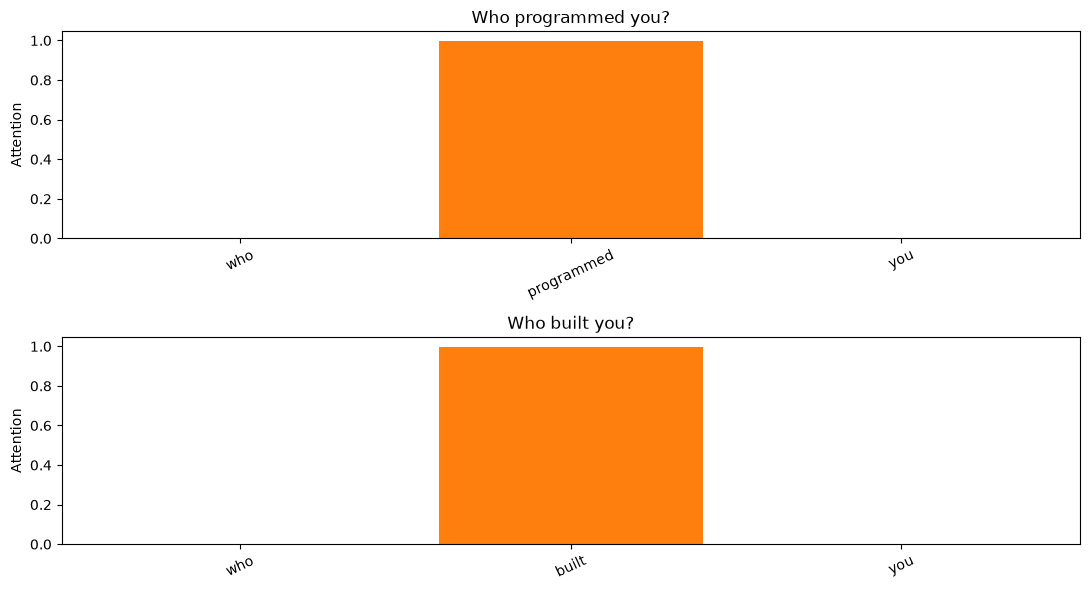

Question: Who programmed you?
  Highest-attention word: 'programmed'; weight=0.9963
  Predicted group: 3; actual group: 3 — People created me.
Question: Who built you?
  Highest-attention word: 'built'; weight=0.9971
  Predicted group: 3; actual group: 3 — People created me.

Task 2 — Comparison:
The two paraphrases have the same labeled answer class, but different wording.
Highest-attention tokens are DIFFERENT.
This shows attention can distribute focus differently across paraphrases.
These weights are learned for classification; they do not prove human-style reasoning.


In [9]:
# TASK 2 — Same meaning, different words; both questions come from answer group 3.
similar_questions = ["Who programmed you?", "Who built you?"]
fig, axes = plt.subplots(2, 1, figsize=(11, 6))
task2_results = []

for ax, query in zip(axes, similar_questions):
    matches = df.index[df["question"].str.lower().eq(query.lower())].tolist()
    assert len(matches) == 1, f"Question not found uniquely: {query!r}"
    i = matches[0]
    words = df.loc[i, "tokens"]
    with torch.no_grad():
        logits, attention_weights = model(X[i:i + 1])
    values = attention_weights[0, :len(words)].cpu().numpy()
    top_index = int(values.argmax())
    predicted_group = index_to_label[int(logits.argmax(dim=1).item())]
    true_group = int(df.loc[i, "answer_id"])
    task2_results.append((df.loc[i, "question"], words[top_index],
                          float(values[top_index]), predicted_group, true_group))

    ax.bar(range(len(words)), values)
    ax.bar(top_index, values[top_index], color="tab:orange")
    ax.set_xticks(range(len(words)), words, rotation=25)
    ax.set_title(df.loc[i, "question"])
    ax.set_ylabel("Attention")

plt.tight_layout()
plt.show()

assert task2_results[0][4] == task2_results[1][4], "The two examples should share an answer class."
for question, top_word, top_weight, pred, target in task2_results:
    print(f"Question: {question}")
    print(f"  Highest-attention word: {top_word!r}; weight={top_weight:.4f}")
    print(f"  Predicted group: {pred}; actual group: {target} — {label_to_answer[target]}")

same = task2_results[0][1] == task2_results[1][1]
print("\nTask 2 — Comparison:")
print("The two paraphrases have the same labeled answer class, but different wording.")
print("Highest-attention tokens are", "the SAME." if same else "DIFFERENT.")
print("This shows attention can distribute focus differently across paraphrases.")
print("These weights are learned for classification; they do not prove human-style reasoning.")
